In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Lab 03 - Logistic Regression

Link to dataset: https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records

In [2]:
list_available_datasets()

NameError: name 'list_available_datasets' is not defined

In [3]:
heart_failure_clinical_records = fetch_ucirepo(id=519)
  
X = heart_failure_clinical_records.data.features
y = heart_failure_clinical_records.data.targets 

In [4]:
# metadata 
heart_failure_clinical_records.metadata

{'uci_id': 519,
 'name': 'Heart Failure Clinical Records',
 'repository_url': 'https://archive.ics.uci.edu/dataset/519/heart+failure+clinical+records',
 'data_url': 'https://archive.ics.uci.edu/static/public/519/data.csv',
 'abstract': 'This dataset contains the medical records of 299 patients who had heart failure, collected during their follow-up period, where each patient profile has 13 clinical features.',
 'area': 'Health and Medicine',
 'tasks': ['Classification', 'Regression', 'Clustering'],
 'characteristics': ['Multivariate'],
 'num_instances': 299,
 'num_features': 12,
 'feature_types': ['Integer', 'Real'],
 'demographics': ['Age', 'Sex'],
 'target_col': ['death_event'],
 'index_col': None,
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 2020,
 'last_updated': 'Mon Feb 26 2024',
 'dataset_doi': '10.24432/C5Z89R',
 'creators': [],
 'intro_paper': {'ID': 286,
  'type': 'NATIVE',
  'title': 'Machine learning can predict survival of patie

In [5]:
# variable information 
heart_failure_clinical_records.variables

,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,age of the patient,years,no
1,anaemia,Feature,Binary,NaN,decrease of red blood cells or hemoglobin,NaN,no
2,creatinine_phosphokinase,Feature,Integer,NaN,level of the CPK enzyme in the blood,mcg/L,no
3,diabetes,Feature,Binary,NaN,if the patient has diabetes,NaN,no
4,ejection_fraction,Feature,Integer,NaN,percentage of blood leaving the heart at each ...,%,no
5,high_blood_pressure,Feature,Binary,NaN,if the patient has hypertension,NaN,no
6,platelets,Feature,Continuous,NaN,platelets in the blood,kiloplatelets/mL,no
7,serum_creatinine,Feature,Continuous,NaN,level of serum creatinine in the blood,mg/dL,no
8,serum_sodium,Feature,Integer,NaN,level of serum sodium in the blood,mEq/L,no
9,sex,Feature,Binary,Sex,woman or man,NaN,no


In [6]:
X.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8


In [7]:
y.head()

,death_event
0,1
1,1
2,1
3,1
4,1


In [8]:
target = y["death_event"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeature names:", X.columns.tolist())
print("\nMissing values in X:", X.isna().sum().sum())
print("\nTarget counts:\n", target.value_counts().sort_index())

X shape: (299, 12)
y shape: (299, 1)

Feature names: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time']

Missing values in X: 0

Target counts:
 death_event
0    203
1     96
Name: count, dtype: int64


In [9]:
X.describe().round(2)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00


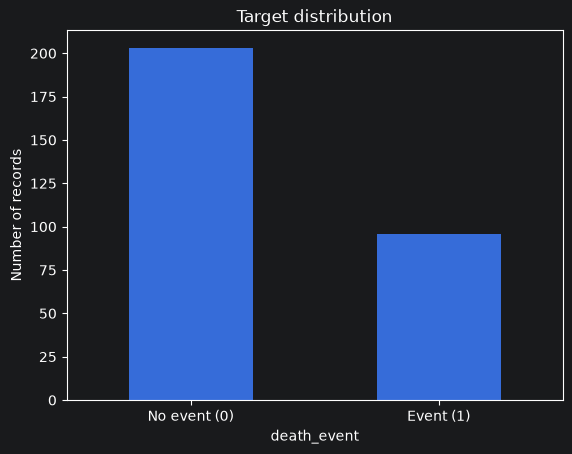

In [10]:
target.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["No event (0)", "Event (1)"], rotation=0)
plt.ylabel("Number of records")
plt.title("Target distribution")
plt.show()

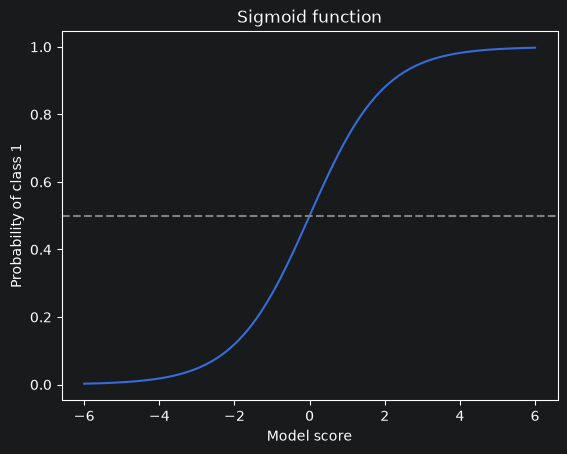

In [11]:
z = np.linspace(-6, 6, 100)
probability = 1 / (1 + np.exp(-z))

plt.plot(z, probability)
plt.axhline(0.5, linestyle="--", color="gray")
plt.xlabel("Model score")
plt.ylabel("Probability of class 1")
plt.title("Sigmoid function")
plt.show()

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.3, random_state=42, stratify=target
)

print("Train records:", len(X_train))
print("Test records:", len(X_test))

Train records: 209
Test records: 90


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [17]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Test accuracy: 0.833

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.92      0.88        61
           1       0.79      0.66      0.72        29

    accuracy                           0.83        90
   macro avg       0.82      0.79      0.80        90
weighted avg       0.83      0.83      0.83        90

